# Alternative: value-aware tokens (combining regular, missing and special values at the token level)

`01_demo_late_fusion_cls.ipynb` implements the requested design. Regular values and missing/special values go through **separate** encoders and meet only at the head, as two pooled CLS vectors:

```
late fusion  (requested):  head([CLS_regular , CLS_missing/special , CLS_snapshot])
```

This notebook shows the variant I recommend trying next to it. Missing and special embeddings go **into the same tokens** as the regular values, so a single encoder sees both:

```
early fusion (alternative): head([CLS_time-series , CLS_snapshot])
hybrid                    : head([CLS_time-series , CLS_missing/special , CLS_snapshot])   (both)
```

### Why token-level fusion should be better in principle

1. **Missingness is informative in context.** "Variable 3 is missing at the last step" means something different depending on what variable 4 did just before, or on whether variable 3 was trending down. With late fusion, attention can never relate a missing cell to the observed values around it. The regular branch only sees a hole, and the missing/special branch only sees the pattern of holes. Only the MLP head can combine them, and by then each side has been compressed into one vector.
2. **It is the standard trick.** BERT replaces a masked word with a learned `[MASK]` embedding *at the same position*. Tabular transformers (FT-Transformer and its variants) likewise give NaN a learned embedding instead of building a separate model of the missingness pattern.
3. **It is cheaper.** One grid encoder instead of two means about 25–40% fewer parameters and a faster epoch.
4. **The requested properties still hold.** There is still **one learned embedding for "missing" and one per special value**, shared by all variables, and still a BERT-style CLS readout.

What you give up: no dedicated "missingness CLS" vector to inspect. The **hybrid** mode keeps one (value-aware tokens *and* the separate branch) if you want both.

### Construction of a value-aware token

For every cell (variable v, step t), with standardised value x and state s ∈ {0 regular, 1 missing, 1+k special k}:

$$e(v,t) \;=\; \mathbb{1}[s=0]\,(w\,x + b) \;+\; E_{\text{state}}[s]$$

* regular cell: its projected value plus the learned "regular" vector `E[0]`;
* missing or special cell: **replaced** by its learned embedding `E[s]`; the imputed 0 or sentinel never enters.

The `P` cell embeddings of a sliding patch are concatenated and projected to `d_model`. From there the token goes through the same factorized (variables, then time) encoder with the 2-D CLS grid.

In [1]:
import sys, os, math, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from tsfusion import (ModelConfig, TrainConfig, RawData, Preprocessor, Trainer, TSFusionTransformer,
                      long_df_to_array, group_columns_by_prefix, build_state, default_target_mode,
                      count_parameters)
from tsfusion.model import ValueStatePatchEmbedding
from tsfusion.synthetic import make_synthetic_dataset

HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda:0" if HAS_GPU else "cpu"
SMALL = not HAS_GPU
RUNS = REPO / "runs" / "demo_fusion_comparison"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("torch", torch.__version__, "| CUDA:", HAS_GPU)

torch 2.15.0+cu132 | CUDA: False


### A value-aware token, step by step (toy example, `state_dim = 4`)

In [2]:
torch.manual_seed(0)
emb = ValueStatePatchEmbedding(n_states=2 + 3, state_dim=4, patch_len=3, d_model=8)
x_patch = torch.tensor([[0.7, 0.0, -999.0]])      # value, imputed 0, sentinel
s_patch = torch.tensor([[0, 1, 3]])               # regular, missing, special code 2
with torch.no_grad():
    regular = (s_patch == 0).unsqueeze(-1).float()
    x_clean = torch.where(s_patch == 0, x_patch, torch.zeros(()))   # the model zeroes non-regular cells
    cells = regular * emb.value_proj(x_clean.unsqueeze(-1)) + emb.state_emb(s_patch)
    show = pd.DataFrame(cells[0].numpy().round(3), index=["t: regular 0.7", "t+1: missing", "t+2: special 2"],
                        columns=[f"e{i}" for i in range(4)])
    show["exactly E[state]?"] = [torch.allclose(cells[0, i], emb.state_emb.weight[s]) for i, s in enumerate([0, 1, 3])]
show

,e0,e1,e2,e3,exactly E[state]?
t: regular 0.7,-0.747,1.081,-0.105,0.074,False
t+1: missing,0.166,0.874,-0.143,-0.112,True
t+2: special 2,0.618,-0.413,-0.841,-2.316,True


Rows 2 and 3 are exactly the learned "missing" and "special 2" vectors. They are the same for every variable, and they don't depend on whatever number was stored in the cell. The three cell vectors are then concatenated (3 × 4) and projected to `d_model` to form the patch token.

## Same data and split as notebook 01

In [3]:
data = make_synthetic_dataset(n_records=6000, n_vars=8, n_special_codes=3, seed=0)
var_names, time_steps, N_SPECIAL = data["var_names"], data["time_steps"], data["n_special_codes"]
ple_groups = group_columns_by_prefix(data["snapshot_ple_df"].columns)
ple_cols = [c for _, cols in ple_groups for c in cols]
group_sizes = [len(cols) for _, cols in ple_groups]

def to_raw(ids):
    kw = dict(value_cols=var_names, record_ids=ids, time_steps=time_steps)
    x, _ = long_df_to_array(data["ts_df"], **kw)
    miss, _ = long_df_to_array(data["missing_df"], fill_value=1, **kw)
    spec, _ = long_df_to_array(data["special_df"], fill_value=0, **kw)
    return RawData(x, miss, spec.astype(np.int64), data["snapshot_ple_df"].loc[ids, ple_cols].to_numpy(),
                   data["y"].loc[ids].to_numpy())

train_raw, val_raw = to_raw(data["train_ids"]), to_raw(data["val_ids"])
print("train", train_raw.x.shape, "val", val_raw.x.shape)

train (4800, 11, 8) val (1200, 11, 8)


## Controlled comparison

Everything is identical except `missing_fusion`: the data, preprocessing, optimiser, schedule, early stopping and selection by validation RMSE. Each variant runs with several seeds, because differences between architectures are often smaller than seed-to-seed noise. Report the mean ± std, never a single run.

The comparison uses the Tweedie loss (p = 1.5, which did well in notebook 01). It works with MSE as well; set `LOSS = "mse"`.

In [4]:
LOSS, POWER = "tweedie", 1.5
SEEDS = [0, 1] if SMALL else [0, 1, 2, 3, 4]
VARIANTS = ["late", "early", "hybrid"]

prep = Preprocessor(N_SPECIAL, group_sizes, target_mode=default_target_mode(LOSS)).fit(train_raw)
train_d, val_d = prep.transform(train_raw), prep.transform(val_raw)
steps_per_epoch = math.ceil(len(train_raw) / 256)

rows, preds = [], {}
for variant in VARIANTS:
    for seed in SEEDS:
        mcfg = ModelConfig(n_vars=len(var_names), n_special_codes=N_SPECIAL, snapshot_group_sizes=group_sizes,
                           patch_len=3, patch_stride=1, d_model=32 if SMALL else 64, ff_mult=2 if SMALL else 4,
                           n_heads=4, n_ts_layers=2, n_special_layers=1, missing_fusion=variant)
        tcfg = TrainConfig(loss=LOSS, tweedie_power=POWER, batch_size=256, max_epochs=40 if SMALL else 150,
                           lr=1e-3, warmup_steps=2 * steps_per_epoch, early_stopping_patience=8,
                           device=DEVICE, seed=seed, train_eval_max_samples=2000, verbose=False,
                           output_dir=str(RUNS / f"{variant}_seed{seed}"))
        t = Trainer(mcfg, tcfg, prep)
        h = t.fit(train_d, val_d)
        best = h.loc[h.val_rmse.idxmin()]
        preds[(variant, seed)] = t.predict(val_d)
        rows.append({"variant": variant, "seed": seed, "params": count_parameters(t.model),
                     "sec_per_epoch": h.epoch_time_s.mean(), "best_epoch": int(best.epoch),
                     **{m: best[f"val_{m}"] for m in ["rmse", "mae", "r2", "nmad", "tweedie_dev"] if f"val_{m}" in best}})
        print(f"{variant:6s} seed {seed}: best epoch {int(best.epoch):2d}  val RMSE {best.val_rmse:8.1f}  R2 {best.val_r2:.3f}")
results = pd.DataFrame(rows)

late   seed 0: best epoch 11  val RMSE   3345.2  R2 0.477


late   seed 1: best epoch  8  val RMSE   3420.3  R2 0.453


early  seed 0: best epoch 14  val RMSE   3228.4  R2 0.513


early  seed 1: best epoch 14  val RMSE   3412.4  R2 0.455


hybrid seed 0: best epoch 15  val RMSE   3313.9  R2 0.486


hybrid seed 1: best epoch 14  val RMSE   3338.9  R2 0.479


In [5]:
metrics = [c for c in ["rmse", "mae", "r2", "nmad", "tweedie_dev"] if c in results]
agg = results.groupby("variant")[metrics + ["params", "sec_per_epoch"]].agg(["mean", "std"]).reindex(VARIANTS)
agg.round(3)

rmse                mae             r2            nmad           \
             mean      std      mean     std   mean    std     mean      std   
variant                                                                        
late     3382.718   53.109  1585.293  79.868  0.465  0.017  949.573   91.413   
early    3320.400  130.132  1598.543  72.326  0.484  0.040  947.168   31.586   
hybrid   3326.389   17.691  1607.900  50.468  0.482  0.006  987.371  101.370   

        tweedie_dev          params      sec_per_epoch         
               mean    std     mean  std          mean    std  
variant                                                        
late         27.946  0.336  64913.0  0.0         9.035  0.420  
early        26.606  0.929  47025.0  0.0         5.544  0.071  
hybrid       27.448  0.597  66369.0  0.0         8.860  0.244

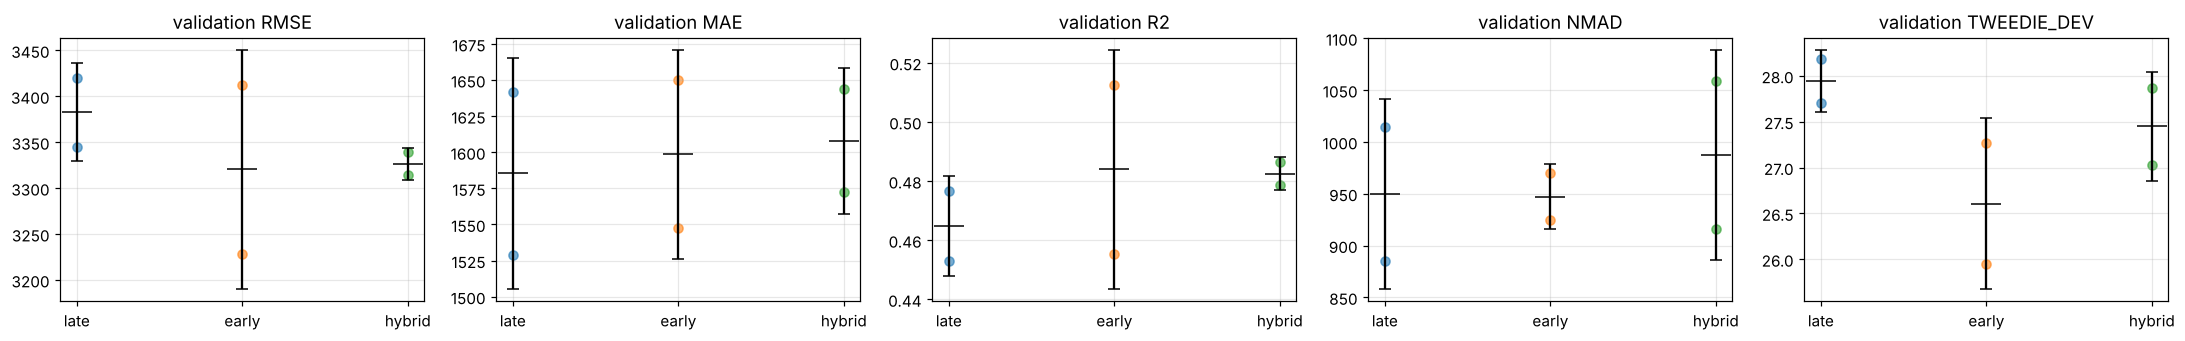

In [6]:
fig, axes = plt.subplots(1, len(metrics), figsize=(4 * len(metrics), 3.2))
for ax, m in zip(axes, metrics):
    for i, v in enumerate(VARIANTS):
        vals = results.loc[results.variant == v, m]
        ax.scatter([i] * len(vals), vals, alpha=0.6)
        ax.errorbar(i, vals.mean(), yerr=vals.std() if len(vals) > 1 else 0, fmt="_", color="k", ms=20, capsize=4)
    ax.set_xticks(range(len(VARIANTS)), VARIANTS); ax.set_title(f"validation {m.upper()}")
plt.tight_layout(); plt.show()

### Where would the difference show up? Error by amount of missing and special data

Overall metrics mix records with no missing data (where all variants should be similar) with records that have a lot. A diagnostic that matters for your data: error as a function of how many cells of the record are missing or special.

In [7]:
state_val = build_state(val_raw.missing, val_raw.special)
n_nonreg = (state_val != 0).sum(axis=(1, 2))
bucket = pd.qcut(n_nonreg, 4, duplicates="drop")                 # quartiles of the count
tab = {}
for v in VARIANTS:
    p = np.mean([preds[(v, s)] for s in SEEDS], axis=0)          # seed-averaged prediction
    err = pd.DataFrame({"abs_err": np.abs(p - val_raw.y), "bucket": bucket})
    tab[v] = err.groupby("bucket", observed=True).abs_err.mean()
tab = pd.DataFrame(tab)
tab.insert(0, "n_records", pd.Series(bucket).value_counts().reindex(tab.index).values)
print("MAE by number of missing/special cells in the record (of", state_val[0].size, "cells)")
tab.round(1)

MAE by number of missing/special cells in the record (of 88 cells)


,n_records,late,early,hybrid
bucket,,,,
"(-0.001, 9.0]",361,1169.5,1151.4,1157.8
"(9.0, 13.0]",286,1449.1,1522.4,1493.7
"(13.0, 18.0]",309,1786.0,1775.7,1791.2
"(18.0, 40.0]",244,1993.9,2097.7,2093.5


## Reading the results and recommendation

* On this synthetic data the gaps between variants are about the size of the seed-to-seed noise. That is expected, because the synthetic target uses missingness through only a few simple effects. **Run the same comparison on your data** (same code, swap the loader). Real missingness and special codes usually carry more context-dependent signal ("special code = account closed" after a falling balance means something different than after a stable one), and that is where token-level fusion helps.
* **Early fusion needs one grid encoder instead of two**: fewer parameters and a shorter epoch (see the `params` and `sec_per_epoch` columns). This matters with many variables, where the `(V+1)·(Np+1)` grid dominates memory.
* **Recommendation:** keep the requested **late** design as the baseline, and add **early** (or **hybrid**, if you want a separate missingness CLS to inspect) as a candidate. Choose on validation, confirm on an untouched test split, and look at error by missingness bucket as above.

### Other options (not implemented here)

| idea | what it does | when to consider |
|---|---|---|
| cell-level tokens (no patching, `patch_len=1`) | every (variable, step) cell is its own token, so a missing cell is never mixed with its neighbours | T = 11 is small, so it is affordable; already possible with `patch_len=1, patch_stride=1` |
| missingness as attention bias | a learned scalar per state is added to the attention logits, so attention learns to trust or ignore missing/special keys | very sparse data, or as an alternative to hard masking |
| FiLM / gating | the state embedding scales and shifts the value embedding instead of being added | when a special code changes how the value should be read |
| snapshot tokens inside the time-series encoder | static tokens join the CLS row, or are cross-attended, so temporal attention is conditioned on snapshot variables | strong static × temporal interactions (e.g. a segment-specific seasonality) |